# HYROX 대회 기록 분석

**정형 데이터(표 형태)로 EDA → 군집 → 회귀 → 분류를 수행한 머신러닝 분석 프로젝트**

## 개요
- 목적: HYROX 대회 기록의 구조 파악 및 이후 분석의 기준값(초 단위) 생성
- 데이터: 92,374행(34열) 중 분석 대상 open·pro 부문 61,832건
- 환경: Python 3.12.15 / pandas 3.0.6 / scikit-learn 1.9.1 (conda `hyrox-analysis`)

## 구성
1. 데이터 불러오기·시간 변환
2. 변환 결과 검증
3. 완주 시간 분포
4. 구간별(런·스테이션·록스존) 기록

## 0. 사전 개념

**핵심: 정형 데이터 분석이며, EDA를 시작으로 군집·회귀·분류로 확장**

### 정형 · 반정형 · 비정형
| 항목 | 정형 | 반정형 | 비정형 |
|---|---|---|---|
| 구조 | 행·열(테이블) | 행·열은 없고 태그·키로 구조를 표시 | 정해진 구조 없음 |
| 저장 | 엑셀, CSV, RDBMS | JSON, XML, HTML | 파일 그대로, NoSQL·데이터 레이크 |
| 예시 | 대회 기록표, 회원 정보, 재고 목록 | 웹 로그, API 응답, 센서 데이터 | 사진, 영상, 음성, 자유 텍스트 |
| 분석 | SQL·표 분석으로 바로 가능 | 파싱 후 표로 변환 | 전처리(특징 추출)·딥러닝 필요 |

- 정형: 스키마(열 이름·형식)가 정의되어 검색·집계·분석이 용이
- 비정형: 분석 전 자연어 처리·이미지 처리 등 전처리 필요
- HYROX 기록: 총 기록·구간 기록·성별·연령대가 열로 구성된 정형 데이터 → 표 기반 모델(scikit-learn) 적용

### 분석 흐름
| 단계 | 학습 유형 | 역할 | 대표 기법 |
|---|---|---|---|
| EDA | - | 구조·분포·이상값·결측치를 시각화와 기초 통계로 파악 | 히스토그램, 박스플롯, 산점도, 상관 분석 |
| 군집 | 비지도 | 정답 없이 유사한 데이터끼리 그룹화 | K-Means, 계층적 군집, DBSCAN |
| 회귀 | 지도 | 입력으로 연속된 숫자(Y) 예측 | 선형 회귀, 랜덤 포레스트 회귀 |
| 분류 | 지도 | 입력으로 미리 정의된 범주(Y) 판별 | 로지스틱 회귀, 랜덤 포레스트 분류 |

- 지도 학습: 정답(Y) 포함 데이터로 학습 / 비지도 학습: 정답 없이 구조 탐색
- EDA의 핵심: 풀 수 있는 문제와 필요한 전처리를 결정
- 단계 연결: 앞 단계 결과가 뒤 단계의 선택 근거 (선형성 확인 → 회귀 모델 선정, 클래스 불균형 확인 → 평가지표 선정)
- 유의: 군집 결과를 분류의 정답으로 사용할 때 군집에 쓴 변수를 입력에 재사용하면 성능이 과대평가됨 (순환)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, openpyxl  # 이후 단계(모델·엑셀 읽기)에 쓸 라이브러리가 설치됐는지 확인
from IPython.display import HTML  # 표 가운데 정렬용 HTML 출력

plt.rc("font", family="Malgun Gothic")  # 한글 깨짐 방지를 위한 폰트 지정(Windows 기준)
plt.rc("axes", unicode_minus=False)

print(pd.__version__, sklearn.__version__)

3.0.6 1.9.1


## 1. 데이터 불러오기와 시간 변환

**핵심: `hh:mm:ss` 문자열을 초 단위 숫자로 변환하여 이후 모든 계산의 기준으로 사용**

### 개념
- 행 = 1회 완주 기록 (선수 식별 열 없음), 열 = 항목
- 문자열 시간은 평균·시각화·모델 입력에 사용 불가 → 초 단위 변환 필요
- 분석 범위: open·pro 부문
- CSV 저장: 엑셀 읽기 약 40초 → 재사용 속도 개선

### 확인 포인트
- `df.shape` = (92374, 34)
- `total_sec` 첫 값 3547 = 첫 행 `00:59:07` (59×60+7)
- 완주 시간 분포: 전체 형태(오른쪽 긴 꼬리 여부), 0분 근처 소수 기록(이상값 후보)

In [2]:
# 파일 위치(notebooks/) 기준 상대 경로로 data/ 접근
df = pd.read_excel("../data/hyrox_results.xlsx")
print(df.shape)

(92374, 34)


In [3]:
df.to_csv("../data/hyrox_results.csv", index=False)  # 재사용용 CSV 저장 (엑셀 읽기 약 40초)

In [4]:
def to_seconds(t):
    """'hh:mm:ss' 형태를 초 단위 정수로 변환"""
    h, m, s = map(int, str(t).split(":"))
    return h * 3600 + m * 60 + s

df["total_sec"] = df["total_time"].apply(to_seconds)
print(df["total_sec"].iloc[0])

3547


open·pro 기록 수(건): 61832


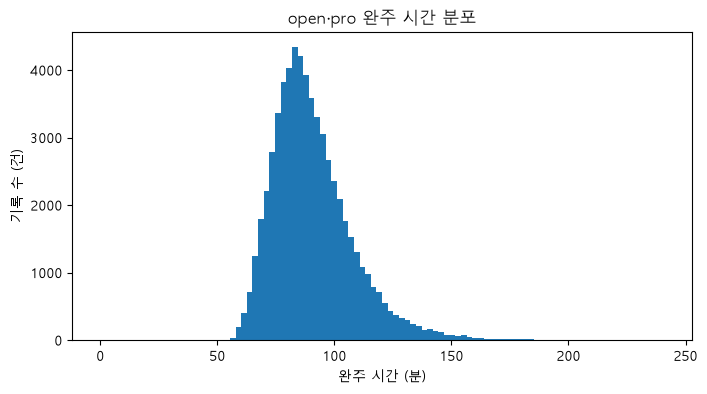

In [5]:
sub = df[df["division"].isin(["open", "pro"])]  # 분석 대상(open·pro) 부분집합
print("open·pro 기록 수(건):", len(sub))

plt.figure(figsize=(8, 4))
plt.hist(sub["total_sec"] / 60, bins=100)  # 가독성을 위해 분 단위로 변환
plt.xlabel("완주 시간 (분)")
plt.ylabel("기록 수 (건)")
plt.title("open·pro 완주 시간 분포")
plt.show()

### 한 줄 정리
- 전체 92,374건의 기록을 불러와 시간을 초 단위로 변환하고, 분석은 open·pro 부문 61,832건으로 진행함

## 2. 변환 결과·행 순서 검증

**핵심: 변환값 `total_sec`을 원본 `total_time`과 대조하고, 원본 행 순서를 확인**

### 개념
- 변환 코드는 실행 후 원본과 비교하여 확인
- 환산 공식: 시 × 3600 + 분 × 60 + 초

### 확인 포인트
- 첫 5행의 `total_sec`이 직접 환산한 값과 일치하는지
- 변환 후 결측이 0건인지
- 원본이 기록순 정렬인지, 대회별로 묶여 있는지

In [6]:
display(df[["total_time", "total_sec"]].head())
print("변환 결측:", df["total_sec"].isna().sum())

,total_time,total_sec
0,00:59:07,3547
1,00:59:27,3567
2,01:00:22,3622
3,01:03:13,3793
4,01:04:00,3840


변환 결측: 0


In [7]:
print("전체 오름차순 여부:", df["total_sec"].is_monotonic_increasing)  # False면 기록순 정렬 아님
print("대회 수:", df["event_id"].nunique(), "/ 연속 블록 수:", (df["event_id"] != df["event_id"].shift()).sum())  # 같으면 대회별로 묶여 있음

전체 오름차순 여부: False
대회 수: 89 / 연속 블록 수: 89


### 결과
- 첫 5행의 `total_sec`이 직접 환산한 값과 일치 (예: `01:03:13` → 3793)
- 변환 결측 0건
- 원본 행 순서: 대회(`event_id`) 89개가 연속된 블록으로 묶여 있고, 전체 기준 완주 시간 오름차순은 아님

### 추정·한계
- 행 순서는 대회별 묶음이므로 앞에서부터 자르는 방식(`head`)으로 표본이나 분할을 만들지 않음 (이후 분할 시 섞거나 대회 단위로 나눌 필요가 있음)

### 한 줄 정리
- 첫 5행의 변환값이 원본과 일치하고, 결측은 0건이며, 원본은 대회별로 묶여 있음

## 3. 완주 시간 분포

**핵심: 요약 통계와 부문별 분포로 완주 시간의 중심·퍼짐·이상값 후보를 파악**

### 개념
- 요약 통계(`describe`): 개수·평균·표준편차·최솟값·사분위수·최댓값
- 평균과 중앙값(50%)의 차이: 한쪽으로 긴 꼬리(이상값 영향)의 단서
- 밀도(`density=True`): 부문별 막대 면적을 각각 1로 맞춘 비율 척도, 기록 수가 다른 부문의 분포 형태를 직접 비교

### 확인 포인트
- 평균과 중앙값의 차이
- 최솟값이 현실적인 완주 시간인지 (0분 근처 기록)
- open·pro 분포의 위치와 겹침

In [8]:
print((sub["total_sec"] / 60).rename("완주 시간(분)").describe().round(1))  # 단위: 분

count    61832.0
mean        90.6
std         17.3
min          0.0
25%         78.8
50%         87.7
75%         99.4
max        240.8
Name: 완주 시간(분), dtype: float64


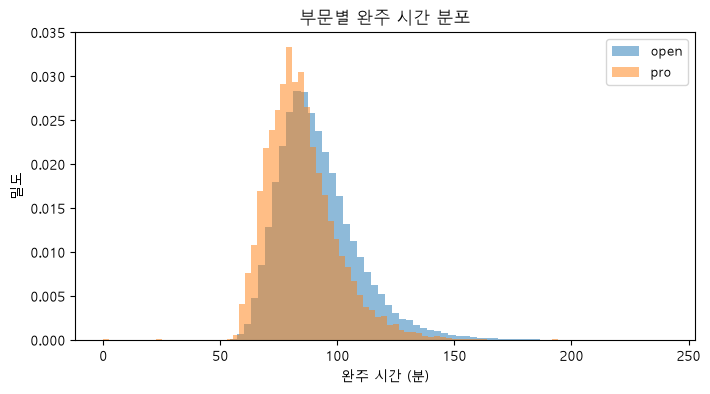

In [9]:
plt.figure(figsize=(8, 4))
for name, g in sub.groupby("division"):
    plt.hist(g["total_sec"] / 60, bins=80, alpha=0.5, density=True, label=name)  # density: 부문별 기록 수 차이 보정
plt.xlabel("완주 시간 (분)")
plt.ylabel("밀도")
plt.title("부문별 완주 시간 분포")
plt.legend()
plt.show()

In [10]:
print((sub.groupby("division")["total_sec"].median() / 60).round(1))  # 부문별 중앙값(분)

division
open    89.0
pro     82.7
Name: total_sec, dtype: float64


In [11]:
print("최솟값(초):", sub["total_sec"].min())
print("0초 기록 행 수:", (sub["total_sec"] == 0).sum())

최솟값(초): 0
0초 기록 행 수: 8


### 결과
- 완주 시간 중앙값 87.7분, 평균 90.6분 (평균 > 중앙값, 오른쪽으로 긴 꼬리)
- 중간 50% 구간 78.8~99.4분, 표준편차 17.3분
- 최솟값 0분(0초 기록 8행) → 이상값 후보, 최댓값 240.8분은 전처리 단계에서 확인
- 부문별 기록 수: open 50,368건, pro 11,464건
- 부문별 중앙값: open 89.0분, pro 82.7분 (pro가 6.3분 빠름), 분포는 넓게 겹침

### 추정·한계
- 0초 기록 8행의 원인(기록 누락, 입력 오류 등)은 전처리 단계에서 확인
- 부문 차이의 원인(선수 수준 vs 부문 기준)은 이 결과만으로 구분 불가

### 한 줄 정리
- 완주 시간 평균은 90.6분이며, 부문별 중앙값은 open 89.0분, pro 82.7분으로 pro가 더 빠름

## 4. 구간별 기록

**핵심: 런·스테이션·록스존 구간별 중앙값을 비교하여 기록을 좌우하는 구간을 파악**

### 개념
- HYROX는 달리기(런)와 운동 스테이션을 8회 반복하며, 구간 열은 런 `run_1~8`, 스테이션 `work_1~8`, 록스존 `roxzone_1~8`
- 스테이션: 운동 구간 (데이터의 열 이름은 `work`)
- 스테이션 순서(공식 대회 규정 기준, 데이터로 확인한 것은 아님): 1 스키에르그, 2 슬레드 푸시, 3 슬레드 풀, 4 버피 브로드 점프, 5 로잉, 6 파머스 캐리, 7 샌드백 런지, 8 월볼
- 록스존(roxzone): 달리기와 운동 사이의 전환 구간, 마지막 스테이션 뒤에는 전환 구간이 없어 8구간 록스존은 해당 없음
- 중앙값 사용: 평균은 이상값(0초 기록 등)에 민감
- 시간 열 24개(`hh:mm:ss`)를 초 단위로 변환하여 계산
- 표시 단위: 표는 분:초, 그래프는 분

### 확인 포인트
- 구간 번호가 커질수록 기록이 어떻게 변하는지
- 런과 스테이션 중 시간 비중이 큰 쪽
- `roxzone_8`이 항상 0인지 (빈 값 여부)


In [12]:
for kind in ["run", "work", "roxzone"]:
    for i in range(1, 9):
        df[f"{kind}_{i}_sec"] = df[f"{kind}_{i}"].apply(to_seconds)  # 시간 열 24개 → 초

sub = df[df["division"].isin(["open", "pro"])]  # 추가한 구간 열(_sec)을 반영하도록 open·pro 부분집합 재생성

구간별 중앙값 (분:초)


구간,런,스테이션,록스존
1,4:31,4:33,0:33
2,5:03,3:09,0:52
3,5:30,5:18,0:56
4,5:31,5:12,0:52
5,5:39,4:54,0:51
6,5:32,2:14,1:07
7,5:31,4:58,1:11
8,6:14,5:52,-


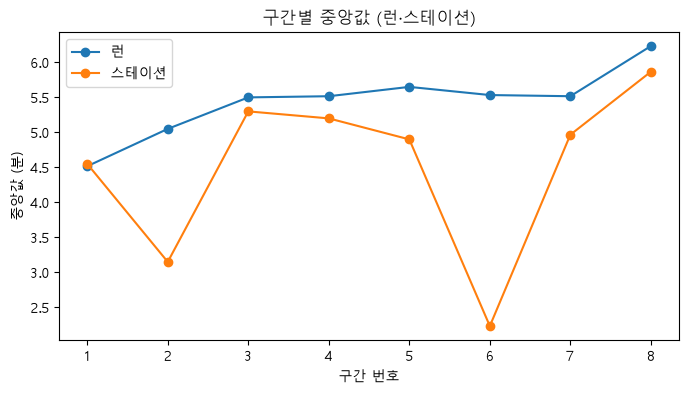

In [13]:
def to_mmss(sec):
    """초를 'm:ss' 형식으로 변환"""
    sec = int(round(sec))
    return f"{sec // 60}:{sec % 60:02d}"

med_sec = pd.DataFrame(
    {
        "런": [sub[f"run_{i}_sec"].median() for i in range(1, 9)],
        "스테이션": [sub[f"work_{i}_sec"].median() for i in range(1, 9)],  # 데이터의 work 열 = 스테이션
        "록스존": [sub[f"roxzone_{i}_sec"].median() for i in range(1, 9)],
    },
    index=range(1, 9),
)  # 행: 구간 번호, 값: 중앙값(초)

print("구간별 중앙값 (분:초)")
table = med_sec.map(to_mmss)
table.loc[8, "록스존"] = "-"  # 8구간 록스존: 마지막 스테이션 뒤 전환 구간 없음(해당 없음)
table.insert(0, "구간", table.index)  # 구간 번호를 첫 번째 열로 이동
display(HTML("<style>.center th, .center td {text-align: center;}</style>" + table.to_html(classes="center", index=False)))

(med_sec[["런", "스테이션"]] / 60).plot(marker="o", figsize=(8, 4))  # 그래프는 분 단위 숫자로 표시
plt.xlabel("구간 번호")
plt.ylabel("중앙값 (분)")
plt.title("구간별 중앙값 (런·스테이션)")
plt.show()

In [14]:
table.loc[8, "록스존"] = "-"  # 8구간 록스존: 대회 구조상 해당 없음(마지막 스테이션 뒤 전환 구간 없음)

구간별 중앙값 (분:초)


구간,런,스테이션,록스존
1,4:31,4:33,0:33
2,5:03,3:09,0:52
3,5:30,5:18,0:56
4,5:31,5:12,0:52
5,5:39,4:54,0:51
6,5:32,2:14,1:07
7,5:31,4:58,1:11
8,6:14,5:52,-


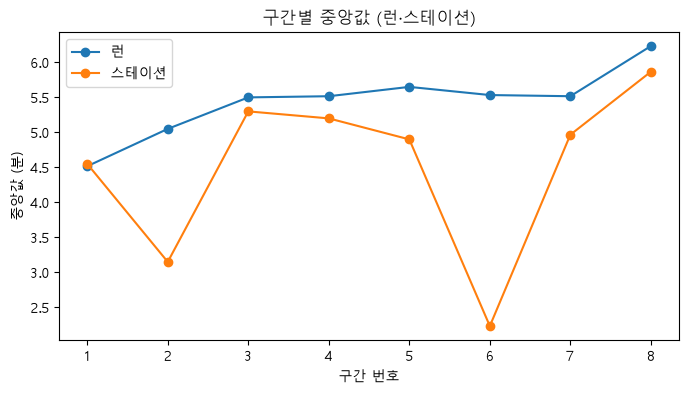

In [15]:
def to_mmss(sec):
    """초를 'm:ss' 형식으로 변환"""
    sec = int(round(sec))
    return f"{sec // 60}:{sec % 60:02d}"

med_sec = pd.DataFrame(
    {
        "런": [sub[f"run_{i}_sec"].median() for i in range(1, 9)],
        "스테이션": [sub[f"work_{i}_sec"].median() for i in range(1, 9)],  # 데이터의 work 열 = 스테이션
        "록스존": [sub[f"roxzone_{i}_sec"].median() for i in range(1, 9)],
    },
    index=range(1, 9),
)  # 행: 구간 번호, 값: 중앙값(초)

print("구간별 중앙값 (분:초)")
table = med_sec.map(to_mmss)
table.loc[8, "록스존"] = "-"  # 8구간 록스존: 마지막 스테이션 뒤 전환 구간 없음(해당 없음)
table.insert(0, "구간", table.index)  # 구간 번호를 첫 번째 열로 이동
display(HTML("<style>.center th, .center td {text-align: center;}</style>" + table.to_html(classes="center", index=False)))

(med_sec[["런", "스테이션"]] / 60).plot(marker="o", figsize=(8, 4))  # 그래프는 분 단위 숫자로 표시
plt.xlabel("구간 번호")
plt.ylabel("중앙값 (분)")
plt.title("구간별 중앙값 (런·스테이션)")
plt.show()

### 결과
- 런: 1구간 4:31 → 2~7구간 5:03~5:39 → 8구간 6:14 (1구간이 가장 빠르고 8구간이 가장 느림)
- 스테이션: 구간별 편차 큼 (2구간 3:09, 6구간 2:14로 짧고 8구간 5:52로 가장 김)
- 록스존: 1구간 0:33 → 7구간 1:11로 증가 경향, 8구간은 해당 없음(`-`)
- `roxzone_8`: 마지막 스테이션 뒤에는 전환 구간이 없어 빈 값(0)으로 채워진 열 → 분석 제외
- 중앙값 단순 합산(근사): 런 약 43.5분, 스테이션 약 36.2분, 록스존(1~7구간) 6분 22초

### 추정·한계
- 후반으로 갈수록 느려지는 원인(피로 누적 등)은 이 표만으로 구분 불가
- 스테이션 구간별 길이 차이는 운동 종류 차이로 보이며, 구간 번호와 운동 종류의 대응은 공식 순서를 적용한 것으로 데이터에서 직접 확인한 것은 아님
- 중앙값의 합은 합의 중앙값과 다르므로 런·스테이션 비중은 근사값

### 한 줄 정리
- 런은 구간이 뒤로 갈수록 길어지고, 스테이션은 구간별 편차가 크며, 시간 비중은 런이 더 큼 (중앙값 합 기준)